# 🔍 MVTec Anomaly Detection Dataset: Exploratory Data Analysis (EDA)
**Project:** Edge Agentic Assistant for Industrial Conveyor Automation (Group 14 / CAP-16)  
**Target Hardware:** Qualcomm Dragonwing QRB2210 Linux MPU (Quad Cortex-A53, 4 GB RAM)  
**Microservice:** `container-cv` (Automated Optical Inspection & Anomaly Detection)  
**Project Requirements:** NFR-04 (Vision Throughput $\ge 10\text{ FPS}$), NFR-08 (Defect Recall $\ge 90\%$)

---

### Objectives of this Notebook:
1. Inspect image dimensions, channels, and structural resolution ($800 \times 800$ native).
2. Quantify industrial anomaly types (cracks, scratches, contaminations, imprint defects).
3. Analyze pixel-level defect mask coverage (% of canvas covered by anomalies).
4. Evaluate downsampling trade-offs for edge INT8 YOLOv8n inference on ARM Cortex-A53.

In [1]:
import os
import io
import re
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
DATA_PATH = os.path.abspath("../data/mvtec_ad/mvtec_train_part0.parquet")
print(f"MVTec Parquet path: {DATA_PATH}")
print(f"File size: {os.path.getsize(DATA_PATH)/(1024*1024):.2f} MB")

MVTec Parquet path: C:\Users\Admin\Documents\COS40005\data\mvtec_ad\mvtec_train_part0.parquet
File size: 287.95 MB


In [2]:
df = pd.read_parquet(DATA_PATH)
print(f"MVTec Partition Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
display(df[['text']].head(5))

MVTec Partition Shape: (252, 4)
Columns: ['image', 'guide', 'text', 'mask_image']


,text
0,An image with 1 color defect on the pill
1,An image with 4 color defect on the pill
2,An image with 1 color defect on the pill
3,An image with 4 color defect on the pill
4,An image with 2 color defect on the pill


In [3]:
def load_pil(cell):
    if cell is None:
        return None
    if isinstance(cell, dict) and "bytes" in cell:
        return Image.open(io.BytesIO(cell["bytes"]))
    if isinstance(cell, bytes):
        return Image.open(io.BytesIO(cell))
    if isinstance(cell, Image.Image):
        return cell
    return None

objects, defect_types, defect_ratios, resolutions = [], [], [], []
sample_img, sample_guide, sample_mask, sample_desc = None, None, None, ""

for idx, row in df.iterrows():
    desc = row.get("text", "")
    words = desc.split()
    obj = words[-1].lower() if words else "unknown"
    objects.append(obj)
    
    m = re.search(r"with \d+ ([a-zA-Z_\s]+) defect", desc)
    if m:
        defect_types.append(m.group(1).strip().lower())
    else:
        defect_types.append("general anomaly")
        
    img = load_pil(row.get("image"))
    if img:
        resolutions.append(img.size)
        
    mask = load_pil(row.get("mask_image"))
    if mask:
        m_arr = np.array(mask)
        pct = (np.sum(m_arr > 0) / m_arr.size) * 100.0
        defect_ratios.append(pct)
        
        if sample_img is None and pct > 0.5:
            sample_img = img
            sample_guide = load_pil(row.get("guide"))
            sample_mask = mask
            sample_desc = desc

print(f"Native Resolution: {resolutions[0][0]} x {resolutions[0][1]} RGB")
print(f"Total Evaluated Samples: {len(df):,}")
print(f"Defect Area Coverage - Mean: {np.mean(defect_ratios):.2f}% (Std: {np.std(defect_ratios):.2f}%)")
print(f"Defect Area Coverage - Min: {np.min(defect_ratios):.3f}%, Max: {np.max(defect_ratios):.2f}%")

Native Resolution: 800 x 800 RGB
Total Evaluated Samples: 252
Defect Area Coverage - Mean: 5.72% (Std: 9.07%)
Defect Area Coverage - Min: 0.050%, Max: 41.00%


In [4]:
# Defect Type Breakdown
defect_counts = Counter(defect_types)
df_def = pd.DataFrame(list(defect_counts.items()), columns=["Anomaly Category", "Sample Count"]).sort_values("Sample Count", ascending=False)
display(df_def.reset_index(drop=True))

,Anomaly Category,Sample Count
0,crack,43
1,defective,27
2,color,25
3,scratch,24
4,contamination,21
5,faulty imprint,19
6,oil,18
7,glue strip,18
8,combined,17
9,gray stroke,16


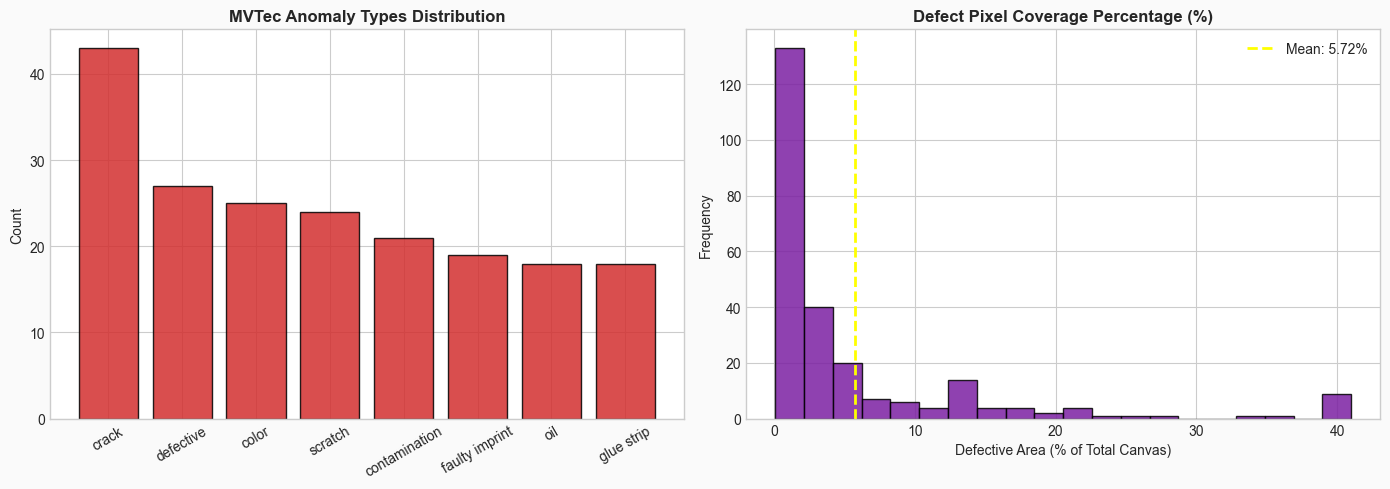

In [5]:
# Summary Distribution Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor("#FAFAFA")

# Anomaly Categories
top_def = df_def.head(8)
axes[0].bar(top_def["Anomaly Category"], top_def["Sample Count"], color="#D32F2F", edgecolor="black", alpha=0.85)
axes[0].set_title("MVTec Anomaly Types Distribution", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=30)

# Defect Pixel Coverage
axes[1].hist(defect_ratios, bins=20, color="#7B1FA2", edgecolor="black", alpha=0.85)
axes[1].axvline(np.mean(defect_ratios), color="yellow", linestyle="--", linewidth=2, label=f"Mean: {np.mean(defect_ratios):.2f}%")
axes[1].set_title("Defect Pixel Coverage Percentage (%)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Defective Area (% of Total Canvas)")
axes[1].set_ylabel("Frequency")
axes[1].legend()

plt.tight_layout()
plt.show()

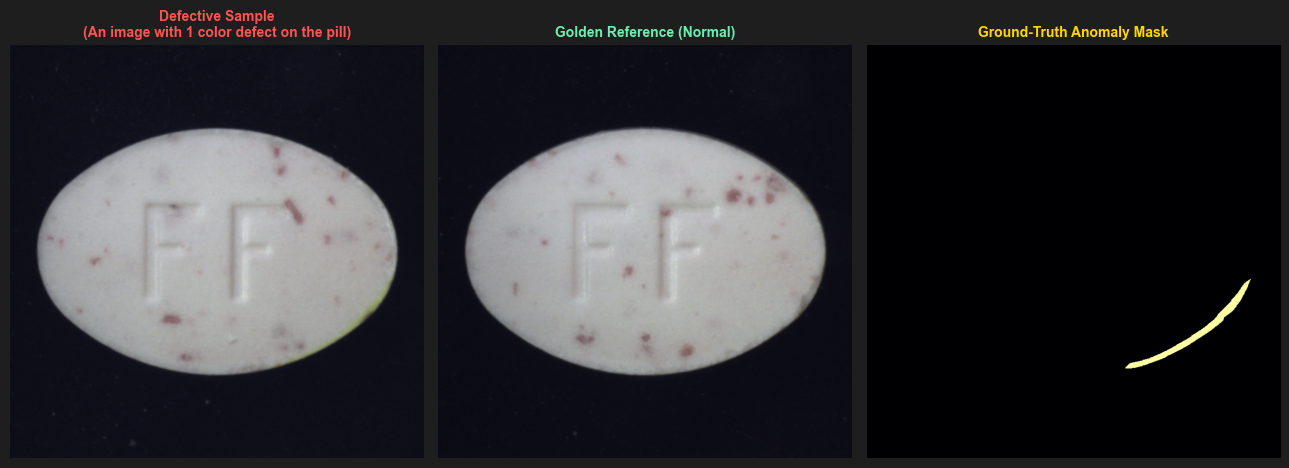

In [6]:
# Sample Anomaly Triplet Visualization
if sample_img and sample_mask:
    fig, axes = plt.subplots(1, 3, figsize=(13, 5))
    fig.patch.set_facecolor("#1E1E1E")
    
    axes[0].imshow(sample_img)
    axes[0].set_title(f"Defective Sample\n({sample_desc})", color="#FF5252", fontsize=10, fontweight="bold")
    
    if sample_guide:
        axes[1].imshow(sample_guide)
        axes[1].set_title("Golden Reference (Normal)", color="#69F0AE", fontsize=10, fontweight="bold")
    else:
        axes[1].axis("off")
        
    axes[2].imshow(sample_mask, cmap="inferno")
    axes[2].set_title("Ground-Truth Anomaly Mask", color="#FFD700", fontsize=10, fontweight="bold")
    
    for ax in axes:
        ax.axis("off")
        
    plt.tight_layout()
    plt.show()

### 🎯 How This Dataset Helps with Fine-Tuning:
1. **Memory-Bank & Normalizing Flow Fine-Tuning (PatchCore / FastFlow)**: Rather than supervised classification requiring thousands of defect labels, pre-trained ImageNet backbones (e.g., WideResNet-50) extract patch-level feature vectors from healthy surface images. Fine-tuning fits a coreset-subsampled memory bank or trains a bijective normalizing flow exclusively on normal distribution manifolds.
2. **Anomaly Threshold Calibration on Subtle Defects**: EDA revealed that industrial defects often occupy $<5\%$ of total component area. The ground-truth pixel masks in MVTec AD allow calibrating detection thresholds and bounding contours, ensuring fine hairline cracks, scratches, and solder voids trigger rejection flags.
3. **Student-Teacher Feature Distillation**: A lightweight student network (e.g., MobileNetV3) is trained to mimic a pre-trained teacher network strictly on defect-free samples. When an anomaly passes through, the student network fails to reproduce the teacher's feature representation, generating an instant pixel-wise anomaly heatmap for sorting.